# 🛡️ LangGraph: Human-in-the-Loop (HITL) Workflow

### 📌 Overview
This notebook implements **Human-in-the-Loop (HITL)** architecture in LangGraph:
1. **Static Breakpoints (`interrupt_before`):** Compiles the graph to pause execution automatically before critical nodes (e.g., publishing to social media, database writes, payments).
2. **Pending State Inspection (`get_state`):** Inspects `snapshot.next` and `snapshot.values` while the graph is paused at a checkpoint.
3. **Approval Resumption:** Resumes paused execution unchanged by passing `None` to `app.invoke()`.
4. **Human State Steering (`update_state`):** Edits the generated content in the checkpoint before resuming execution.
5. **Dynamic Interrupts (`interrupt()` & `Command`):** The modern in-node interrupt pattern that solicits real-time human input during node execution.

---

### 🗺️ Graph Topology

```text
┌─────────┐       ┌────────────────┐       ⚠️ [BREAKPOINT]       ┌────────────────┐       ┌───────┐
│  START  │ ────► │   draft_post   │ ───►  [Human Supervisor]  ───► │  publish_post  │ ────► │  END  │
└─────────┘       └────────────────┘       (Approve / Edit)       └────────────────┘       └───────┘
```

*Execution Flow:* `START` ➔ `draft_post` ➔ **PAUSE** ➔ Human Review/Edit ➔ `publish_post` ➔ `END`

In [1]:
import os
from typing import NotRequired, TypedDict
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

# Load environment variables
load_dotenv()

# Verify OpenRouter key
if not os.getenv("OPENROUTER_API_KEY"):
    raise ValueError(
        "OPENROUTER_API_KEY is missing. Please add it to your .env file: "
        "OPENROUTER_API_KEY=sk-or-v1-..."
    )

### 2. Initialize LLM via OpenRouter
We initialize `ChatOpenAI` pointing to OpenRouter's `openrouter/free` router.

In [2]:
# OpenRouter configuration with Free Models Router
model = ChatOpenAI(
    model="openrouter/free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    temperature=0.7,
)

### 3. Define Graph State Schema
The state tracks:
* `topic`: Initial prompt topic.
* `draft`: Article or post draft generated by the AI node.
* `reviewer_notes`: Notes or edits added by the human operator (`NotRequired` initially).
* `published_status`: Final confirmation status from the publishing node.

In [3]:
class ContentState(TypedDict):
    topic: str
    draft: NotRequired[str]
    reviewer_notes: NotRequired[str]
    published_status: NotRequired[str]

### 4. Define Workflow Nodes
* **`draft_post`:** Generates a draft post from the topic.
* **`publish_post`:** Simulates an external side-effect (e.g. publishing to LinkedIn or a CMS). This is the sensitive node we will guard.

In [4]:
def draft_post(state: ContentState) -> dict:
    """Generates an initial social media post draft."""
    messages = [
        (
            "system",
            "You are a professional tech writer. Write an engaging, punchy post under 250 characters.",
        ),
        ("human", f"Write a post about: '{state['topic']}'"),
    ]
    response = model.invoke(messages)
    return {"draft": str(response.content)}


def publish_post(state: ContentState) -> dict:
    """CRITICAL SIDE-EFFECT: Publishes the approved draft to external platforms."""
    draft = state["draft"]
    # Simulated publishing API call
    return {
        "published_status": f"SUCCESS: Post published live to production! [Content: {draft}]"
    }

### 5. Build and Compile Graph with Breakpoint (`interrupt_before`)
* A checkpointer (`MemorySaver`) is **mandatory** because LangGraph must save state while paused.
* `interrupt_before=["publish_post"]`: Pauses execution whenever the graph is about to run the `publish_post` node.

In [5]:
# 1. Initialize StateGraph
builder = StateGraph(ContentState)
builder.add_node("draft_post", draft_post)
builder.add_node("publish_post", publish_post)

# 2. Connect linear pipeline
builder.add_edge(START, "draft_post")
builder.add_edge("draft_post", "publish_post")
builder.add_edge("publish_post", END)

# 3. Compile with persistence and static breakpoint
checkpointer = MemorySaver()
app = builder.compile(
    checkpointer=checkpointer,
    interrupt_before=["publish_post"],  # Graph halts here
)

### 6. Visualize Graph Topology
Evaluating the compiled `app` object renders the interactive diagram.

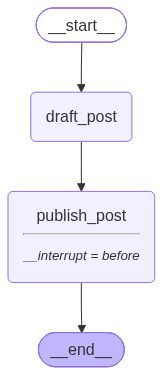

In [6]:
app

### 7. Scenario A: Execution Halts & Human Approves
1. We invoke the graph with an initial topic.
2. The graph executes `draft_post`, then **halts** right before `publish_post`.
3. We inspect `snapshot.next` to verify it is paused.
4. We pass `None` to `app.invoke()` to approve and let `publish_post` execute.

In [7]:
config_a = {"configurable": {"thread_id": "thread-approval-1"}}

print("=== TRIGGERING GRAPH (Halts before publish_post) ===\n")
app.invoke({"topic": "LangGraph Persistence & Memory"}, config=config_a)

# 1. Inspect checkpoint state
snapshot_a = app.get_state(config_a)
print(f"Current Status: {'PAUSED at breakpoint' if snapshot_a.next else 'COMPLETED'}")
print(f"Next Node to Execute: {snapshot_a.next}")
print(f"\nGenerated Draft Pending Review:\n{snapshot_a.values.get('draft')}\n")

# 2. Human reviews and APPROVES by passing None
print("=== HUMAN SUPERVISOR: [APPROVE] ===\n")
res_a = app.invoke(None, config=config_a)
print(res_a["published_status"])

=== TRIGGERING GRAPH (Halts before publish_post) ===

Current Status: PAUSED at breakpoint
Next Node to Execute: ('publish_post',)

Generated Draft Pending Review:
Stop building amnesiac agents. 🧠 LangGraph Persistence & Memory adds statefulness and long-term recall to your LLM workflows. Resume, remember, and scale. #LangGraph #AI

=== HUMAN SUPERVISOR: [APPROVE] ===

SUCCESS: Post published live to production! [Content: Stop building amnesiac agents. 🧠 LangGraph Persistence & Memory adds statefulness and long-term recall to your LLM workflows. Resume, remember, and scale. #LangGraph #AI]


### 8. Scenario B: Human Edits the Draft (`update_state`) Before Publishing
In this scenario, the human reviewer is unsatisfied with the AI draft. 
Using `app.update_state()`, the reviewer updates the `draft` text in the checkpoint *before* resuming. When `publish_post` executes, it uses the human's revised content.

In [8]:
config_b = {"configurable": {"thread_id": "thread-edit-2"}}

print("=== TRIGGERING GRAPH (New Session) ===\n")
app.invoke({"topic": "Why Agents Need Human Supervision"}, config=config_b)

# 1. Inspect initial AI draft
snapshot_b = app.get_state(config_b)
print(f"Original AI Draft:\n{snapshot_b.values.get('draft')}\n")

# 2. Human supervisor edits the draft in the checkpoint
print("=== HUMAN SUPERVISOR: [EDIT DRAFT] ===\n")
revised_text = (
    "AI agents are powerful, but enterprise systems need human oversight. "
    "LangGraph HITL makes guardrails seamless!"
)

app.update_state(
    config_b,
    {"draft": revised_text, "reviewer_notes": "Shortened for clarity and punchiness by editor."},
)

# 3. Resume execution to publish the edited text
res_b = app.invoke(None, config=config_b)
print(f"Result:\n{res_b['published_status']}")

=== TRIGGERING GRAPH (New Session) ===

Original AI Draft:
AI agents are powerful, but not perfect. Without human oversight, they can hallucinate, drift, or cause chaos. Keep humans in the loop for accuracy, ethics, and control. Automation works best with a human safety net.

=== HUMAN SUPERVISOR: [EDIT DRAFT] ===

Result:
SUCCESS: Post published live to production! [Content: AI agents are powerful, but enterprise systems need human oversight. LangGraph HITL makes guardrails seamless!]


### 9. Modern Dynamic In-Node Interrupts (`interrupt` & `Command`)
In addition to static node breakpoints, modern LangGraph supports dynamic **in-node interrupts**. 
A node pauses midway through its execution to solicit feedback and receives the human response directly through `Command(resume=...)`.

In [9]:
class DynamicState(TypedDict):
    task: str
    feedback: NotRequired[str]
    result: NotRequired[str]


def interactive_node(state: DynamicState) -> dict:
    """A node that pauses mid-execution to ask a human operator for guidance."""
    task = state["task"]

    # 1. Pause execution and send a question to the human
    operator_guidance = interrupt(f"Task '{task}' requires clarification. Proceed? (yes/no)")

    # 2. Execution resumes here with operator_guidance populated
    if str(operator_guidance).lower() == "yes":
        outcome = f"Task '{task}' executed with operator approval."
    else:
        outcome = f"Task '{task}' aborted per operator instruction."

    return {"feedback": str(operator_guidance), "result": outcome}


# Build dynamic interrupt graph
dyn_builder = StateGraph(DynamicState)
dyn_builder.add_node("step", interactive_node)
dyn_builder.add_edge(START, "step")
dyn_builder.add_edge("step", END)

dyn_app = dyn_builder.compile(checkpointer=MemorySaver())

dyn_config = {"configurable": {"thread_id": "dynamic-demo"}}

# Step 1: Run graph until it hits interrupt()
print("=== DYNAMIC INTERRUPT: RUNNING UNTIL PROMPT ===")
step_1 = dyn_app.invoke({"task": "Deploy Model to Production"}, config=dyn_config)

# Inspect the interrupt payload
dyn_snapshot = dyn_app.get_state(dyn_config)
interrupt_data = dyn_snapshot.tasks[0].interrupts[0].value
print(f"Interrupt Received: '{interrupt_data}'\n")

# Step 2: Resume with human response using Command(resume=...)
print("=== RESUMING WITH Command(resume='yes') ===")
final_dyn_state = dyn_app.invoke(Command(resume="yes"), config=dyn_config)
print(f"Final State Result:\n{final_dyn_state['result']}")

=== DYNAMIC INTERRUPT: RUNNING UNTIL PROMPT ===
Interrupt Received: 'Task 'Deploy Model to Production' requires clarification. Proceed? (yes/no)'

=== RESUMING WITH Command(resume='yes') ===
Final State Result:
Task 'Deploy Model to Production' executed with operator approval.
